# Estatística Geral

## Estimação de parâmetros estatísticos


Praticamente qualquer característica de uma população pode ser estimada a partir de uma amostra aleatória. Os estimadores mais usados são a média amostral (x̄), o desvio padrão amostral (s) e a proporção amostral (p̂), que estimam, respectivamente, a média (μ), o desvio padrão (σ) e a proporção (p) da população.

### Estimativa pontual:

Uma estimativa pontual resume o parâmetro em um único número calculado a partir da amostra. Os estimadores pontuais mais comuns são:

| Parâmetro populacional | Estimador |
|---|---|
| $\mu$ | $\bar{x} = \dfrac{1}{n} \sum_{i=1}^{n} x_i$ |
| $\sigma$ | $s = \sqrt{\dfrac{\sum_{i=1}^{n} (x_i - \bar{x})^2}{n - 1}}$ |
| $p$ | $\hat{p} = \dfrac{x}{n}$, em que $x$ é o número de itens da amostra com a característica de interesse e $n$ é o tamanho da amostra |

### Estimativa intervalar ou Intervalo de confiança:

Em vez de um único número, a estimativa intervalar fornece uma faixa de valores plausíveis para o parâmetro, construída a partir da amostra. Associado ao intervalo há um grau de confiança, que expressa o quanto confiamos que o procedimento captura o valor verdadeiro.

O grau de confiança (também chamado de nível ou coeficiente de confiança) vale 1 - α: é a probabilidade de que o procedimento produza um intervalo que contenha o parâmetro. O valor α corresponde a uma área sob a curva, dividida entre as duas caudas, como na figura abaixo:

A área central, $1 - \alpha$, é o grau de confiança; cada cauda fica com $\alpha/2$:

In [1]:
# Funções auxiliares usadas para desenhar os gráficos deste notebook
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm, t


def virgula(ax):
    """Mostra os números dos eixos com vírgula decimal."""
    fmt = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)


def duas_caudas(dist, critico, rotulos_x, rotulo_centro, rotulo_cauda, titulo=None):
    """Curva com as duas caudas além de ±critico sombreadas (intervalo de confiança)."""
    x = np.linspace(-4, 4, 400)
    fig, ax = plt.subplots(figsize=(5, 2.8))
    ax.plot(x, dist.pdf(x), color="tab:blue")
    for xs in (np.linspace(-4, -critico, 100), np.linspace(critico, 4, 100)):
        ax.fill_between(xs, dist.pdf(xs), color="0.45")
    ax.vlines([-critico, critico], 0, dist.pdf(critico), color="k", lw=1.5)
    ax.text(0, dist.pdf(0) * 0.45, rotulo_centro, ha="center", fontsize=11)
    for lado in (-1, 1):
        ax.annotate(rotulo_cauda, xy=(lado * (critico + 0.35), dist.pdf(critico) * 0.3),
                    xytext=(lado * 3.3, dist.pdf(0) * 0.45), ha="center", fontsize=11,
                    arrowprops=dict(arrowstyle="->"))
    ax.set_xticks([-critico, critico])
    ax.set_xticklabels(rotulos_x)
    ax.set_yticks([])
    ax.set_ylim(bottom=0)
    if titulo:
        ax.set_title(titulo, fontsize=10)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.show()

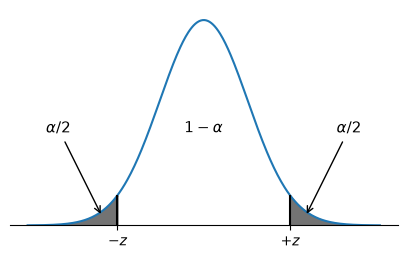

In [2]:
duas_caudas(norm, 1.96, ["$-z$", "$+z$"], "$1 - \\alpha$", "$\\alpha/2$")

Os níveis de confiança mais usados são 90% (α = 0,10), 95% (α = 0,05) e 99% (α = 0,01). O de 95% é o mais comum, por equilibrar precisão (intervalos não muito largos) e confiabilidade (grau de confiança alto).

Aumentar o nível de confiança alarga o intervalo; e, para um mesmo nível, quanto mais largo o intervalo, menos ele nos diz sobre o valor verdadeiro do parâmetro.

Como interpretar: se repetíssemos a amostragem muitas vezes e, a cada vez, calculássemos um intervalo de 100(1-α)% de confiança, cerca de 100(1-α)% desses intervalos conteriam o valor verdadeiro do parâmetro.

Na prática temos uma única amostra e um único intervalo, que contém ou não o parâmetro; não faz sentido atribuir uma probabilidade a esse intervalo específico. O correto é dizer que temos 100(1-α)% de confiança de que o intervalo observado contém o valor verdadeiro.

### Intervalo de confiança para a média quando σ é conhecido:

Uma envasadora de suco trabalha com garrafas de volume médio nominal de 500 ml, e o processo tem desvio padrão conhecido de 4 ml. Depois de uma manutenção na máquina, suspeita-se que a média mudou. Uma amostra de 100 garrafas teve volume médio de 497 ml.

Encontre a estimativa pontual e um intervalo de 95% de confiança para o novo volume médio, supondo que o desvio padrão do processo não mudou.

A melhor estimativa pontual da média populacional (μ) é a média amostral (x̄): o novo volume médio é estimado em 497 ml.

Para o intervalo usamos o fato de que, pelo Teorema Central do Limite, a média amostral tem distribuição aproximadamente normal, e o desvio padrão da população (σ = 4 ml) é conhecido. Assim, o intervalo é construído com a distribuição normal:

Intervalo de confiança para $\mu$ quando o desvio padrão populacional $\sigma$ é conhecido:

$$\bar{x} \pm z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}}$$

O valor crítico separa, na distribuição das médias amostrais, a região central (de área 1 - α) das duas caudas. É o valor z que deixa área α/2 em cada cauda e pode ser lido na tabela da normal padrão.

O valor crítico é denotado por:

$$z_{\alpha/2}$$

Para os níveis de confiança mais utilizados, os valores críticos obtidos na
tabela da distribuição normal padrão são:

| Grau de confiança | $\alpha$ | $z_{\alpha/2}$ |
|---|---|---|
| 90% | 0,10 | 1,64 |
| 95% | 0,05 | 1,96 |
| 99% | 0,01 | 2,58 |

Valores arredondados para duas casas; a célula abaixo os calcula com o `scipy`.

In [3]:
# Valores críticos z de alfa/2 para os níveis de confiança mais usados
from scipy.stats import norm

for confianca in (0.90, 0.95, 0.99):
    alfa_ic = 1 - confianca
    print(f"{confianca:.0%}: alfa = {alfa_ic:.2f}, z = {norm.ppf(1 - alfa_ic / 2):.4f}")

90%: alfa = 0.10, z = 1.6449
95%: alfa = 0.05, z = 1.9600
99%: alfa = 0.01, z = 2.5758


Ao estimar uma média populacional μ com uma amostra, a margem de erro E é a maior diferença que esperamos, com confiança 1 - α, entre a média amostral x̄ e a média verdadeira μ (por isso também é chamada de erro máximo da estimativa). Ela é o valor crítico multiplicado pelo desvio padrão das médias amostrais, σ/√n:

$$E = z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}}$$

Voltando ao exemplo, temos:

- $\bar{x} = 497$ ml
- $n = 100$
- $\sigma = 4$ ml
- nível de confiança de 95%, ou seja, $\alpha = 0{,}05$

E o intervalo de confiança desejado é:

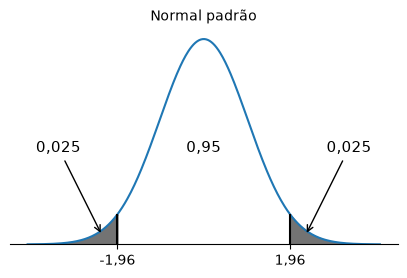

In [4]:
# 95% de confiança: 0,025 em cada cauda, valores críticos ±1,96
duas_caudas(norm, norm.ppf(0.975), ["-1,96", "1,96"], "0,95", "0,025", titulo="Normal padrão")

Como o nível de confiança é 95%, a área entre 0 e z é 0,95/2 = 0,475. Procurando 0,475 no corpo da tabela da normal padrão, encontramos z = 1,96.

A margem de erro (E):

$$E = z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}} = 1{,}96 \cdot \frac{4}{\sqrt{100}} = 0{,}784 \text{ ml}$$

O intervalo de confiança é I.C. = [x̄ - E ; x̄ + E] = [497 - 0,784 ; 497 + 0,784] = [496,216 ml ; 497,784 ml]. Ou seja, com 95% de confiança, o volume médio atual das garrafas está entre 496,216 ml e 497,784 ml.

In [32]:
z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [33]:
# Informar o Grau de confiança, exemplo 90% = 90
# Primeiramente, carregar a tabela z acima.
def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

Z(95)

1.96

In [31]:
#Calculando I.C para média quando σ é conhecido.

#Variáveis do enunciado:
Média_amostral = 497
N_amostras = 100
Desvio_populacional = 4
Grau_de_conf = 95 #(%)

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_médias_amostrais = Desvio_populacional/(N_amostras**0.5)

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_médias_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Média_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1} a {2}" .format(Grau_de_conf, Média_amostral-E, Média_amostral+E))

Valor de Alpha:  0.05
Valor crítico:  1.96
Margem de Erro:  0.784
I.C = [497-0.784 ; 497+0.784]


Pode-se afirmar com 95% de confiança que a média varia de 496.216 a 497.784


Uma empresa quer estimar o tempo médio de deslocamento casa-trabalho dos seus funcionários. Levantamentos anteriores indicam desvio padrão populacional de 6 minutos. Numa amostra aleatória de 25 funcionários, o tempo médio foi de 38 minutos.
- a) Qual é a estimativa pontual do tempo médio de deslocamento?
    R: 38 minutos, pois a estimativa pontual da média é a própria média amostral.

- b) Construa um intervalo de 90% de confiança para o tempo médio de deslocamento. R: z de α/2 = 1,64, E = 1,968, IC = [36,032 ; 39,968]

In [35]:
#Calculando I.C para média quando σ é conhecido.

#Variáveis do enunciado:
Média_amostral = 38 #minutos
N_amostras = 25 #funcionários
Desvio_populacional = 6 #minutos
Grau_de_conf = 90 #(%)

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_médias_amostrais = Desvio_populacional/(N_amostras**0.5)

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_médias_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Média_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f}" .format(Grau_de_conf, Média_amostral-E, Média_amostral+E))

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  1.968
I.C = [38-1.968 ; 38+1.968]


Pode-se afirmar com 90% de confiança que a média varia de  36.0320 a  39.9680


Uma pessoa pretende abrir um food truck e quer estimar o faturamento médio semanal desse tipo de negócio. Suponha que o faturamento semanal seja normal, com desvio padrão conhecido de R\$ 150,00. Durante dez semanas ela anotou o faturamento de um food truck semelhante (dados fictícios):

    2450 2610 2380 2720 2550 2490 2660 2530 2400 2610

Construa e interprete um intervalo de 92% de confiança para o faturamento médio semanal. R: x̄ = 2540 ; z de α/2 = 1,75 ; I.C. = [2456,99 ; 2623,01]

In [37]:
import numpy as np
Dados = [2450, 2610, 2380, 2720, 2550, 2490, 2660, 2530, 2400, 2610]

In [40]:
#Calculando I.C para média quando σ é conhecido.

#Variáveis do enunciado:
Média_amostral = round(np.mean(Dados),4) #reais
N_amostras = 10 #semanas
Desvio_populacional = 150 #reais
Grau_de_conf = 92 #(%)

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_médias_amostrais = Desvio_populacional/(N_amostras**0.5)

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_médias_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Média_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f}" .format(Grau_de_conf, Média_amostral-E, Média_amostral+E))

Valor de Alpha:  0.08
Valor crítico:  1.75
Margem de Erro:  83.0098
I.C = [2540.0-83.0098 ; 2540.0+83.0098]


Pode-se afirmar com 92% de confiança que a média varia de 2456.9902 a 2623.0098


### Determinação do tamanho da amostra:

Partindo da expressão da margem de erro (E) e resolvendo em relação ao tamanho
da amostra n, obtemos:

$$E = z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}} \quad \Rightarrow \quad \sqrt{n} = \frac{z_{\alpha/2} \cdot \sigma}{E} \quad \Rightarrow \quad n = \left(\frac{z_{\alpha/2} \cdot \sigma}{E}\right)^2$$

Raramente o cálculo de n dá um número inteiro. Nesse caso, arredonda-se sempre para cima: com um n um pouco maior a margem de erro desejada fica garantida, enquanto arredondar para baixo deixaria a amostra pequena demais.

A fórmula usa σ, o desvio padrão da população. Se ele não for conhecido, pode-se usar um valor preliminar, por exemplo:
1. Uma estimativa grosseira pela regra prática:
    σ ≈ Amplitude/4
2. Um estudo piloto: coletar uma primeira amostra aleatória (de pelo menos uns 30 valores), calcular o desvio padrão amostral s e usá-lo no lugar de σ.

### Exemplo:
Uma ONG quer estimar o gasto médio mensal com transporte dos estudantes universitários de uma cidade. Ela deseja ter 95% de confiança de que a média amostral fique a menos de R\$ 20,00 da média verdadeira, e um levantamento anterior indica σ = R\$ 180,00. Qual deve ser o tamanho da amostra?

Temos α = 0,05 (z = 1,96), margem de erro E = 20 e σ = 180. Aplicando a fórmula do tamanho amostral:

$$n = \left(\frac{z_{\alpha/2} \cdot \sigma}{E}\right)^2 = \left(\frac{1{,}96 \cdot 180}{20}\right)^2 = 311{,}1696 \quad \Rightarrow \quad n = 312 \text{ (arredondando para cima)}$$

Refaça esse exercício considerando agora:
- a) Margem de erro igual a R\$ 40,00. R: n = 77,7924, ou seja, 78

In [48]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 40 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 180 #reais
Grau_de_conf = 95 #(%)

N_finita = False
N_populacional = 0

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("O número de amostras ideal é: ",N_amostras)

O número de amostras ideal é:  78.0


Refaça esse exercício considerando agora:
- b) Margem de erro igual a R\$ 10,00 e nível de confiança de 85%. R: z = 1,44, n = 671,8464, ou seja, 672

In [44]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 10 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 180 #reais
Grau_de_conf = 85 #(%)

N_finita = False
N_populacional = 0

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("O número de amostras ideal é: ",N_amostras)

O número de amostras ideal é:  672.0


O cálculo anterior supõe uma população infinita (ou muito grande). Se a população é finita, de tamanho N, a margem de erro ganha um fator de correção:

$$E = z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}} \cdot \sqrt{\frac{N - n}{N - 1}}$$

Isolando n nessa expressão:

$$n = \frac{N \cdot \sigma^2 \cdot z_{\alpha/2}^2}{(N - 1) \cdot E^2 + \sigma^2 \cdot z_{\alpha/2}^2}$$

### Exemplo:
Uma rede de clínicas tem 350 colaboradores e quer estimar o número médio de horas extras mensais por colaborador. Um estudo anterior indica σ = 12 horas. Quantos colaboradores devem ser pesquisados para ter 90% de confiança de que a média amostral fique a menos de 2 horas da média verdadeira?

Temos α = 0,10 (z = 1,64), E = 2, σ = 12 e uma população finita com N = 350. Aplicando a fórmula com correção para população finita:

$$n = \frac{350 \cdot 12^2 \cdot 1{,}64^2}{(350 - 1) \cdot 2^2 + 12^2 \cdot 1{,}64^2} \approx 76{,}0139 \quad \Rightarrow \quad n = 77$$

Devemos pesquisar pelo menos 77 colaboradores, escolhidos ao acaso.

Refaça esse exercício considerando agora:
- a) Tamanho populacional desconhecido (mantendo-se as outras características do enunciado). R: n = 96,8256, ou seja, 97 colaboradores

In [21]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 2 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 12 #horas
Grau_de_conf = 90 #(%)

N_finita = False
N_populacional = 350

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  2
Desvio_populacional:  12
O número de amostras ideal é:  97.0


Refaça esse exercício considerando agora:
- b) Margem de erro igual a 4 horas (mantendo-se as outras características do enunciado). R: n = 22,7012, ou seja, 23 colaboradores

In [22]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 4 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 12 #horas
Grau_de_conf = 90 #(%)

N_finita = True
N_populacional = 350

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  4
Desvio_populacional:  12
O número de amostras ideal é:  23.0


Refaça esse exercício considerando agora:
- c) Nível de confiança de 80% (mantendo-se as outras características do enunciado). R: z de α/2 = 1,28, n = 50,5998, ou seja, 51 colaboradores

In [54]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 2 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 12 #horas
Grau_de_conf = 80 #(%)

N_finita = True
N_populacional = 350

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.2
Valor crítico:  1.28
Margem de Erro:  2
Desvio_populacional:  12
O número de amostras ideal é:  51.0


### Exercício:
Uma associação comercial planeja uma pesquisa para estimar o gasto médio mensal com energia elétrica dos pequenos comércios de um bairro. Ela quer 95% de confiança de que a média amostral fique a no máximo R\$ 40 da média real. Um estudo piloto indica desvio padrão de R\$ 300.
- a) Qual o tamanho de amostra necessário? R: n = 216,09, ou seja, 217 comércios.

In [27]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 40 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 300 #reais
Grau_de_conf = 95 #(%)

N_finita = False
N_populacional = 0

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.05
Valor crítico:  1.96
Margem de Erro:  40
Desvio_populacional:  300
O número de amostras ideal é:  217.0


- b) Se a margem de erro desejada for de R\$ 20, qual o tamanho de amostra necessário? R: n = 864,36, ou seja, 865 comércios

In [28]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 20 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 300 #reais
Grau_de_conf = 95 #(%)

N_finita = False
N_populacional = 0

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.05
Valor crítico:  1.96
Margem de Erro:  20
Desvio_populacional:  300
O número de amostras ideal é:  865.0


- c) O bairro tem 250 pequenos comércios. Qual deve ser o tamanho da amostra para 92% de confiança? (Mantendo-se inalteradas as outras informações do enunciado) R: z de α/2 = 1,75, n = 102,2310, ou seja, 103 comércios.

In [29]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 40 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 300 #reais
Grau_de_conf = 92 #(%)

N_finita = True
N_populacional = 250

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.08
Valor crítico:  1.75
Margem de Erro:  40
Desvio_populacional:  300
O número de amostras ideal é:  103.0


### Intervalo de confiança para a média quando σ é desconhecido:
Até aqui usamos a normal padrão (Z) porque o desvio padrão populacional σ era conhecido. Quando σ não é conhecido, usamos o desvio padrão amostral s no seu lugar e trocamos a normal pela distribuição t de Student, proposta por William Gosset (1876-1937).

O uso da t supõe que a população seja aproximadamente normal. Mesmo assim, não basta usar a tabela Z: estimar σ por s, principalmente em amostras pequenas, acrescenta incerteza. Para manter o nível de confiança, o intervalo precisa ficar mais largo, e isso é feito trocando o valor crítico z de α/2 por um valor crítico t de α/2, que é maior.

#### Propriedades importantes da distribuição t-Student:
1. Há uma distribuição t para cada tamanho de amostra:

    Ela é indexada pelos graus de liberdade (g.l.), iguais a n - 1. Na figura abaixo aparecem as distribuições t para n = 4, n = 6 e n = 11.

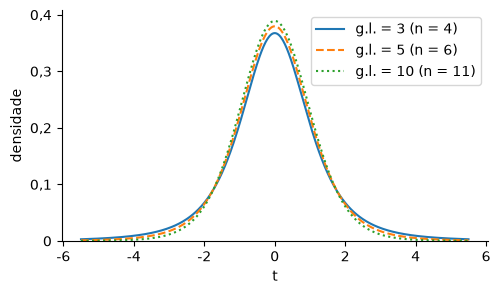

In [5]:
# Distribuições t-Student com 3, 5 e 10 graus de liberdade (n = 4, 6 e 11)
x_graf = np.linspace(-5.5, 5.5, 400)
fig, ax = plt.subplots(figsize=(5.5, 3))
for gl, estilo in ((3, "-"), (5, "--"), (10, ":")):
    ax.plot(x_graf, t.pdf(x_graf, gl), ls=estilo, label=f"g.l. = {gl} (n = {gl + 1})")
ax.set_xlabel("t")
ax.set_ylabel("densidade")
ax.set_ylim(bottom=0)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

2. Tem o mesmo formato de sino, simétrico, da normal padrão, mas é mais achatada, o que reflete a maior variabilidade das amostras pequenas.

    Note que a t tem mais área nas caudas.

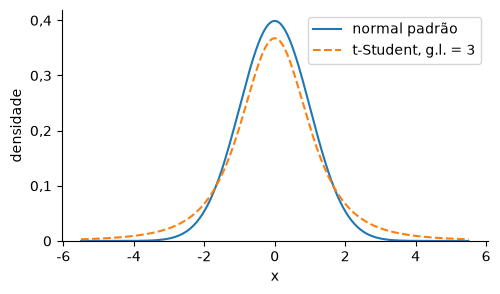

In [6]:
# t-Student com 3 graus de liberdade comparada à normal padrão
x_graf = np.linspace(-5.5, 5.5, 400)
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(x_graf, norm.pdf(x_graf), label="normal padrão")
ax.plot(x_graf, t.pdf(x_graf, 3), ls="--", label="t-Student, g.l. = 3")
ax.set_xlabel("x")
ax.set_ylabel("densidade")
ax.set_ylim(bottom=0)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

3. Sua média é 0, como na normal padrão.

4. Seu desvio padrão é maior que 1 e depende do tamanho da amostra (na normal padrão, σ = 1).

5. Quanto maior a amostra, mais a t se aproxima da normal padrão.

Com σ desconhecido, a margem de erro da estimativa de μ passa a ser calculada com a distribuição t:

$$E = t_{\alpha/2} \cdot \frac{s}{\sqrt{n}}$$

em que $t_{\alpha/2}$ tem $n - 1$ graus de liberdade.

#### Exemplo:
Em testes destrutivos, cada unidade testada é perdida, por isso as amostras costumam ser pequenas. Um fabricante de capacetes testou 10 unidades até a ruptura e obteve força média de ruptura de 4820 N, com desvio padrão de 310 N. Suponha que a força de ruptura tenha distribuição aproximadamente normal.
Determine:

- a) A melhor estimativa pontual de μ, a força média de ruptura de todos os capacetes desse modelo.
- b) A estimativa intervalar de 95% de confiança para μ.

A melhor estimativa pontual de μ é a média amostral: 4820 N.

Para o intervalo usamos a distribuição t-Student, porque:
- o desvio padrão da população (σ) é desconhecido;
- a população é aproximadamente normal.

Construindo o intervalo de confiança:

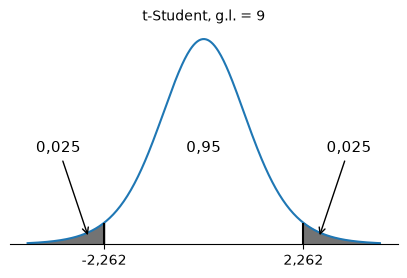

In [7]:
# 95% de confiança com 9 graus de liberdade: 0,025 em cada cauda
duas_caudas(t(9), t.ppf(0.975, 9), ["-2,262", "2,262"], "0,95", "0,025", titulo="t-Student, g.l. = 9")

**Valor crítico:** na tabela t-Student, a linha de $n - 1 = 10 - 1 = 9$ graus de liberdade e a coluna de área $\alpha/2 = 0{,}025$ na cauda superior dão $t_{\alpha/2} = 2{,}262$ (conferido com o `scipy` na célula abaixo).

**Margem de erro:**

$$E = t_{\alpha/2} \cdot \frac{s}{\sqrt{n}} = 2{,}262 \cdot \frac{310}{\sqrt{10}} \approx 221{,}75$$

**Intervalo de confiança:**

$$\bar{x} \pm E = 4820 \pm 221{,}75 \quad \Rightarrow \quad [4598{,}25 ; 5041{,}75]$$

**Interpretação:** com 95% de confiança, a força média de ruptura dos capacetes desse modelo está entre 4598,25 N e 5041,75 N.

In [8]:
# Valor crítico t para 95% de confiança e n - 1 = 9 graus de liberdade
from scipy.stats import t

print("t =", round(t.ppf(1 - 0.05 / 2, 9), 3))

t = 2.262


#### Exercício:
Doze estudantes de uma universidade, escolhidos ao acaso, anotaram quanto gastaram com alimentação durante uma semana. A média foi de R\$ 210,00, com desvio padrão de R\$ 35,00. Construa e interprete um intervalo de 98% de confiança para o gasto médio semanal com alimentação dos estudantes dessa universidade, supondo que a população seja aproximadamente normal. R: t = 2,718 ; E = 27,4617 ; I.C. = [182,54 ; 237,46]

In [65]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [70]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]

In [72]:
#Calculando I.C para média quando σ é desconhecido.

#Variáveis do enunciado:
Média_amostral = 210 #reais
N_amostras = 12 #estudantes
Desvio_amostral = 35 #reais
Grau_de_conf = 98 #(%)
Desvio_populacional = 0 #O enunciado tem apenas desvio amostral,
#por isso o uso de t-student e não z.

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = T(N_amostras, Grau_de_conf)
Desvio_médias_amostrais = Desvio_amostral/(N_amostras**0.5)

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_médias_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Média_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f}" .format(Grau_de_conf, Média_amostral-E, Média_amostral+E))

Valor de Alpha:  0.02
Valor crítico:  2.718
Margem de Erro:  27.4617
I.C = [210-27.4617 ; 210+27.4617]


Pode-se afirmar com 98% de confiança que a média varia de 182.5383 a 237.4617


### Intervalo de confiança para a proporção:
Muitas vezes o parâmetro de interesse é uma proporção p, como a fração de clientes que renovam uma assinatura ou a fração de pedidos entregues com atraso.
A notação que vamos utilizar é:

- $p$: proporção populacional;
- $\hat{p} = \dfrac{x}{n}$: proporção amostral, em que $x$ é o número de sucessos em uma amostra de tamanho $n$.

Assim como a média amostral estima a média populacional, a proporção amostral (p̂) é a estimativa pontual da proporção populacional (p).

A proporção amostral é a média de uma variável que vale 1 (sucesso) ou 0 (fracasso). Por isso, os resultados sobre a distribuição da média amostral também valem para ela.

Aqui construímos o intervalo usando a aproximação normal para a distribuição de p̂, o que exige n.p̂ >= 5 e n.(1 - p̂) >= 5.

A margem de erro é o valor crítico multiplicado pelo desvio padrão estimado de p̂:

$$E = z_{\alpha/2} \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}}$$

O intervalo de confiança é p̂ +- E.

Exemplo: numa inspeção de 150 peças escolhidas ao acaso, 9 apresentaram defeito (p̂ = 0,06). Construa um intervalo de 87% de confiança para a proporção de peças defeituosas da produção:

In [1]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [2]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]

In [15]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 150 #peças
Ocorrências = 9 #peças defeituosas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 87 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.13
Valor crítico:  1.51
Margem de Erro:  0.0293
I.C = [0.06-0.0293 ; 0.06+0.0293]


Pode-se afirmar com 87% de confiança que a média varia de   0.0307 a   0.0893 ou, de   3.0700% a   8.9300%


Com os mesmos dados do exemplo anterior:
- a) Encontre os intervalos com 80% e 99% de confiança.
       Resposta 80% de confiança:
       z =1,28 ; E=0,0248 ; I.C.=[0,0352 ; 0,0848]
       Resposta 99% de confiança:
       z =2,58 ; E=0,0500 ; I.C.=[0,0100 ; 0,1100]

In [76]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 150 #peças
Ocorrências = 9 #peças defeituosas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 80 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.2
Valor crítico:  1.28
Margem de Erro:  0.0248
I.C = [0.06-0.0248 ; 0.06+0.0248]


Pode-se afirmar com 80% de confiança que a média varia de   0.0352 a   0.0848 ou, de   3.5200% a   8.4800%


In [77]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 150 #peças
Ocorrências = 9 #peças defeituosas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 99 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = 2.58  # z de α/2 para 99% (2,5758 no scipy); a busca na tabela empata entre 2,57 e 2,58, então fixamos 2,58 como na tabela da célula 14
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.01
Valor crítico:  2.58
Margem de Erro:  0.05
I.C = [0.06-0.05 ; 0.06+0.05]


Pode-se afirmar com 99% de confiança que a média varia de   0.0100 a   0.1100 ou, de   1.0000% a  11.0000%


- b) Compare os intervalos obtidos.
       Ao aumentarmos o nível de confiança, houve um aumento da margem de erro e,consequentemente, um aumento da amplitude do intervalo.

#### Exercício 5
Uma pesquisa fictícia com 1000 pessoas (450 homens e 550 mulheres) perguntou se eram favoráveis à semana de trabalho de quatro dias. Entre os entrevistados que trabalham, 600 estão em regime remoto e 80 em regime presencial. Os resultados estão na tabela abaixo.

| Grupo | Favoráveis à semana de quatro dias |
|---|---|
| Homens | 63% |
| Mulheres | 47% |
| Pessoas em trabalho remoto | 58% |
| Pessoas em trabalho presencial | 35% |

Construa um intervalo de 98% de confiança para:
- a) A proporção de pessoas em trabalho remoto favoráveis à semana de quatro dias. R: z = 2,33, [53,31% ; 62,69%]

In [78]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [79]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]

In [80]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 600 #pessoas
Ocorrências = 0.58*N_amostras #pessoas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 98 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.02
Valor crítico:  2.33
Margem de Erro:  0.0469
I.C = [0.58-0.0469 ; 0.58+0.0469]


Pode-se afirmar com 98% de confiança que a média varia de   0.5331 a   0.6269 ou, de  53.3100% a  62.6900%


Construa um intervalo de 98% de confiança para:
- b) A proporção de pessoas em trabalho presencial favoráveis à semana de quatro dias. R: z = 2,33, [22,57% ; 47,43%]

In [81]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 80 #pessoas
Ocorrências = 0.35*N_amostras #pessoas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 98 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.02
Valor crítico:  2.33
Margem de Erro:  0.1243
I.C = [0.35-0.1243 ; 0.35+0.1243]


Pode-se afirmar com 98% de confiança que a média varia de   0.2257 a   0.4743 ou, de  22.5700% a  47.4300%


Construa um intervalo de 98% de confiança para:
- c) A proporção de mulheres contrárias à semana de quatro dias. R: z = 2,33, [48,04% ; 57,96%]

In [87]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 550 #pessoas
Ocorrências = 0.53*N_amostras #pessoas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 98 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.02
Valor crítico:  2.33
Margem de Erro:  0.0496
I.C = [0.53-0.0496 ; 0.53+0.0496]


Pode-se afirmar com 98% de confiança que a média varia de   0.4804 a   0.5796 ou, de  48.0400% a  57.9600%


### Determinação do tamanho da amostra:
Isolando n na expressão da margem de erro da proporção:

$$E = z_{\alpha/2} \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}} \quad \Rightarrow \quad n = \frac{z_{\alpha/2}^2 \cdot \hat{p}(1 - \hat{p})}{E^2}$$

A expressão depende de p̂, que pode vir de um estudo piloto ou de pesquisas anteriores. Sem essa informação usa-se p̂ = 0,5, o que garante um tamanho de amostra suficiente qualquer que seja a proporção verdadeira: o produto p̂.(1-p̂) é máximo, igual a 0,25, quando p̂ = 0,5, como mostra a tabela:

| $\hat{p}$ | $1 - \hat{p}$ | $\hat{p}(1 - \hat{p})$ |
|---|---|---|
| 0,1 | 0,9 | 0,09 |
| 0,2 | 0,8 | 0,16 |
| 0,3 | 0,7 | 0,21 |
| 0,4 | 0,6 | 0,24 |
| **0,5** | **0,5** | **0,25** |
| 0,6 | 0,4 | 0,24 |
| 0,7 | 0,3 | 0,21 |
| 0,8 | 0,2 | 0,16 |
| 0,9 | 0,1 | 0,09 |

Lembre-se de arredondar o tamanho da amostra para cima quando ele não for inteiro.

#### Exemplo 6
Uma fintech quer estimar a porcentagem de clientes que usam o pagamento parcelado pelo Pix, com margem de erro de três pontos percentuais e 95% de confiança. Quantos clientes devem ser pesquisados?
- a) Suponha que um levantamento anterior indique que 22% dos clientes usam esse recurso.
- b) Suponha que não haja nenhuma informação prévia sobre p̂.

Queremos o tamanho de amostra para estimar a porcentagem de clientes que usam o Pix parcelado, com margem de erro de 3% (0,03) e 95% de confiança, ou seja, α = 0,05 e z = 1,96.
- a) O levantamento anterior sugere p̂ = 22% = 0,22. Dessa forma:

$$n = \frac{z_{\alpha/2}^2 \cdot \hat{p}(1 - \hat{p})}{E^2} = \frac{1{,}96^2 \cdot 0{,}22 \cdot (1 - 0{,}22)}{0{,}03^2} \approx 732{,}47 \quad \Rightarrow \quad n = 733$$

Devemos pesquisar ao menos 733 clientes selecionados aleatoriamente.

- b) Como não há conhecimento prévio de p̂, adotaremos o valor de 0,5:

$$n = \frac{z_{\alpha/2}^2 \cdot \hat{p}(1 - \hat{p})}{E^2} = \frac{1{,}96^2 \cdot 0{,}5 \cdot (1 - 0{,}5)}{0{,}03^2} \approx 1067{,}11 \quad \Rightarrow \quad n = 1068$$

Para ter 95% de confiança de que a porcentagem amostral fique a menos de 3 pontos percentuais da porcentagem verdadeira, devemos pesquisar 1068 clientes escolhidos ao acaso. Comparando com os 733 da letra a), vemos que, sem informação prévia sobre p̂, é preciso uma amostra maior para obter a mesma precisão.

A expressão:

$$n = \frac{z_{\alpha/2}^2 \cdot \hat{p}(1 - \hat{p})}{E^2}$$

vale para populações infinitas (ou muito grandes). Para uma população finita, de tamanho N, a margem de erro ganha o fator de correção:

$$E = z_{\alpha/2} \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}} \cdot \sqrt{\frac{N - n}{N - 1}}$$

onde N é o tamanho da população.

Isolando n:

$$n = \frac{N \cdot \hat{p}(1 - \hat{p}) \cdot z_{\alpha/2}^2}{\hat{p}(1 - \hat{p}) \cdot z_{\alpha/2}^2 + (N - 1) \cdot E^2}$$

#### Exemplo 7
A coordenação de um curso técnico quer estimar, com margem de erro de 5% e 97% de confiança, a proporção de alunos que trabalham durante o curso. Atualmente há 480 alunos matriculados. Qual é o tamanho mínimo da amostra?
- a) Estima-se que a proporção populacional seja de 30%.
- b) Não há base para estimar a proporção populacional.

A margem de erro desejada é 5% (0,05) e o nível de confiança é 97%, ou seja, α = 0,03 e z = 2,17. A população tem N = 480 alunos.

- a) Estima-se que p̂ = 30% = 0,30. Dessa forma:

$$n = \frac{480 \cdot 0{,}30 \cdot (1 - 0{,}30) \cdot 2{,}17^2}{0{,}30 \cdot (1 - 0{,}30) \cdot 2{,}17^2 + (480 - 1) \cdot 0{,}05^2} \approx 217{,}0984 \quad \Rightarrow \quad n = 218$$

Deve-se amostrar, no mínimo, 218 alunos.

- b) Como não há conhecimento prévio de p̂, adotaremos o valor de 0,5:

$$n = \frac{480 \cdot 0{,}5 \cdot (1 - 0{,}5) \cdot 2{,}17^2}{0{,}5 \cdot (1 - 0{,}5) \cdot 2{,}17^2 + (480 - 1) \cdot 0{,}05^2} \approx 237{,}9509 \quad \Rightarrow \quad n = 238$$

Nesse caso seria preciso amostrar 238 alunos.

#### Exercício 6
Você vai estimar a proporção de crianças de um município fictício que estão com a vacinação em dia. O cadastro municipal tem 1500 crianças. Com 90% de confiança e erro amostral de 4%, determine:
- a) O tamanho da amostra. R: n = 328,4486, ou seja, 329 crianças.

In [1]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [2]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]

In [8]:
#Calculando Número de amostras (N) para a Proporção.

import numpy as np

#Variáveis do enunciado:
Erro = 4 #%  Margem de erro em %
Proporção_amostral = 50 #%  p̂ de 50% quando não dado no enunciado
Grau_de_conf = 90 #(%)

N_finita = True
N_populacional = 1500 #crianças

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
E = Erro/100
Prop_amostral = Proporção_amostral/100

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * (Prop_amostral * (1-Prop_amostral)) * Valor_crítico**2) / 
    (((Prop_amostral * (1-Prop_amostral)) * Valor_crítico**2) + ((N_populacional -1) * E**2)))
else:
    N_amostras = np.ceil((Valor_crítico**2 * (Prop_amostral * (1-Prop_amostral))) / E**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Proporção amostral: ",Prop_amostral)
print("\n")
print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  0.04
Proporção amostral:  0.5


O número de amostras ideal é:  329.0


- b) Considerando agora que 70% das crianças estejam com a vacinação em dia, qual seria o tamanho da amostra? R: n = 285,9137, ou seja, 286 crianças.

In [9]:
#Calculando Número de amostras (N) para a Proporção.

import numpy as np

#Variáveis do enunciado:
Erro = 4 #%  Margem de erro em %
Proporção_amostral = 70 #%  p̂ de 50% quando não dado no enunciado
Grau_de_conf = 90 #(%)

N_finita = True
N_populacional = 1500 #crianças

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
E = Erro/100
Prop_amostral = Proporção_amostral/100

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * (Prop_amostral * (1-Prop_amostral)) * Valor_crítico**2) / 
    (((Prop_amostral * (1-Prop_amostral)) * Valor_crítico**2) + ((N_populacional -1) * E**2)))
else:
    N_amostras = np.ceil((Valor_crítico**2 * (Prop_amostral * (1-Prop_amostral))) / E**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Proporção amostral: ",Prop_amostral)
print("\n")
print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  0.04
Proporção amostral:  0.7


O número de amostras ideal é:  286.0
